# SecondLook | 03 Modelling: Predicting Default Risk

**Goal:** train a model that estimates each applicant's **probability of default (PD)**, prove it works on data it has never seen, and turn its scores into **lending decisions that make business sense**.

**Business question (reminder):** *Among applicants a lender would decline, which ones are actually safe to approve, and what realistic changes would get the rest approved?* This notebook answers the first half by building and evaluating the risk model. Steps 5–6 (SHAP and path to approval) answer the second half.

**The ML workflow we follow** (from the bootcamp's "Introduction to Machine Learning" module):

```
features.parquet ─► choose inputs ─► stratified train/test split ─► baseline model (logistic regression)
                                                                 ─► main model (LightGBM + 5-fold CV)
                 ─► evaluate on the untouched test set ─► choose the approval cutoff by PROFIT ─► save
```

**How we judge the models:**

| Metric | What it tells us | Why we use it |
|---|---|---|
| **ROC AUC** | How well the model *ranks* risky applicants above safe ones (0.5 = random, 1.0 = perfect) | Our main metric. EDA showed **accuracy is useless** here: predicting "everyone repays" scores 91.9% |
| **PR AUC** | Ranking quality focused on the rare defaulters | More sensitive to the minority class; random = 0.08 |
| **Brier score** | How close the predicted probabilities are to reality (lower is better) | PD feeds the profit calculation and the letters, so it must be *honest*, not just well-ranked |
| **Precision / recall** at the cutoff | Of the applicants we decline, how many really would default; of all defaulters, how many we catch | Translates the model into lending outcomes |
| **Profit** | Money made under stated assumptions | What a lender actually cares about |

## 1. Setup

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL, PROCESSED_DIR, RANDOM_STATE
from secondlook.features import load_features, META_PATH as FEATURES_META
from secondlook import modeling as M

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. Load the features and choose the model inputs

We load the 161-column table from Step 3 and decide what the model is **allowed** to see:

- **Excluded:** `SK_ID_CURR` (an ID, no information) and `TARGET` (the answer).
- **Excluded on purpose:** `CODE_GENDER`. Gender showed a real difference in default rates in EDA, but deciding loans by gender is discriminatory and legally restricted in many countries. It stays in the data **only for the fairness audit**, so we can check that the model's decisions don't disadvantage either group.
- **Categorical columns** (text, e.g. `OCCUPATION_TYPE`) are converted to Pandas `category` type with a **fixed list of categories taken from the training data**, so the app later encodes new applicants in exactly the same way.

In [2]:
df = load_features()
feats, cats = M.model_columns(df)
nums = [c for c in feats if c not in cats]

print(f"Applicants: {len(df):,}")
print(f"Model inputs: {len(feats)}  ({len(nums)} numeric, {len(cats)} categorical)")
print(f"Excluded: {ID_COL}, {TARGET_COL}, protected: {M.PROTECTED_COLS}")
print("\nCategorical inputs:", cats)

Applicants: 307,511
Model inputs: 158  (143 numeric, 15 categorical)
Excluded: SK_ID_CURR, TARGET, protected: ['CODE_GENDER']

Categorical inputs: ['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


## 3. Train/test split

We hold back **20% of applicants as a test set** that no model sees during training or tuning. It plays the role of *future applicants*: the final scores we report come only from this set.

The split is **stratified** on `TARGET`, so both parts keep the same 8.07% default rate. With a random (non-stratified) split, the test set could end up with noticeably more or fewer defaulters by chance, which would make our results look better or worse than they really are.

In [3]:
train, test = M.split(df)
categories = {c: sorted(train[c].dropna().unique().tolist()) for c in cats}   # learned from TRAIN only
X_train, X_test = M.prepare_X(train, feats, cats, categories), M.prepare_X(test, feats, cats, categories)
y_train, y_test = train[TARGET_COL], test[TARGET_COL]

pd.DataFrame({"applicants": [len(train), len(test)],
              "defaults": [int(y_train.sum()), int(y_test.sum())],
              "default rate": [y_train.mean(), y_test.mean()]}, index=["train (80%)", "test (20%)"])

,applicants,defaults,default rate
train (80%),246008,19860,0.0807
test (20%),61503,4965,0.0807


**Interpretation:** 246,008 applicants for training and 61,503 for testing, and **both have exactly 8.07% defaults**, as intended. Note that the category lists are learned from the training set only: using anything from the test set during training would be **data leakage** and would inflate our results.

## 4. Baseline: logistic regression

Every model needs a **baseline** to beat. Logistic regression is the classic credit-scoring model: simple, fast and interpretable (each feature gets one weight). It can't handle missing values or text on its own, so it needs a **preprocessing pipeline**:

| Step | Applied to | Why |
|---|---|---|
| Median imputation (+ "was missing" indicator columns) | Numeric columns | Fills gaps without losing the fact that a value was missing |
| Signed log transform | Money columns (`AMT_*`, totals) | EDA showed money is heavily right-skewed; log makes it closer to symmetric |
| Standard scaling | All numeric columns | Puts features on the same scale so no feature dominates just because of its units |
| One-hot encoding (rare categories grouped) | Text columns | Turns categories into 0/1 columns the model can use |
| `C = 0.1` regularisation | The model | Shrinks weights slightly to reduce overfitting with ~300 input columns |

Using a scikit-learn `Pipeline` means every step is **learned on the training data only** and then applied unchanged to the test data.

In [4]:
start = time.time()
logit = M.make_logistic(nums, cats).fit(train[feats], y_train)
pd_logit = logit.predict_proba(test[feats])[:, 1]
logit_scores = M.scores(y_test, pd_logit)
print(f"Trained in {time.time() - start:.0f}s")
pd.Series(logit_scores, name="logistic regression (test set)").to_frame()

Trained in 16s


,logistic regression (test set)
roc_auc,0.7729
pr_auc,0.2660
brier,0.0667
mean_pd,0.0803
actual_rate,0.0807


**Interpretation:** the baseline reaches a **test ROC AUC of about 0.773**: if we pick one random defaulter and one random non-defaulter, the model gives the defaulter the higher risk score about 77% of the time. That's already well above the best single feature (`EXT_SOURCE_MEAN`, 0.717), so combining features works. The **average predicted PD (8.0%) matches the actual default rate (8.07%)**, so its probabilities are realistic.

This is the bar LightGBM has to clear.

## 5. Main model: LightGBM

**LightGBM** builds hundreds of small decision trees one after another; each new tree focuses on the mistakes of the trees before it (*gradient boosting*). We chose it because EDA and Step 3 showed it suits this data:

- **Missing values are handled natively**, which matters with uneven history coverage (28–95%).
- **Non-linear patterns are learned automatically**, like the inverted-U loan-to-income effect from EDA that a linear model can't capture.
- **Interactions are learned too** (e.g. a high loan-to-income ratio matters more for a young applicant with no bureau history).
- It's fast on 250,000 rows, and it works directly with SHAP for per-applicant explanations (Step 5).

### 5.1 Five-fold cross-validation

A single train/validation split can be lucky or unlucky. **Stratified 5-fold cross-validation** splits the *training* set into 5 parts, trains on 4 and validates on the 5th, and repeats so every part is used for validation once. This tells us how stable the model is.

**Early stopping** chooses the number of trees: training stops once validation AUC hasn't improved for 200 trees, which prevents the model from memorising the training data.

Key settings: learning rate 0.03 (small, careful steps), at least 100 applicants per leaf, and each tree seeing a random 80% of rows and 50% of features. All of these guard against overfitting. *(This takes about 5 minutes.)*

In [5]:
start = time.time()
cv = M.cross_validate_lgbm(X_train, y_train)
print(f"\nCross-validated AUC: {cv['mean_auc']:.4f} ± {cv['std_auc']:.4f}   ({time.time() - start:.0f}s)")

  fold 1: AUC 0.7816  (1201 trees)


  fold 2: AUC 0.7831  (1052 trees)


  fold 3: AUC 0.7845  (865 trees)


  fold 4: AUC 0.7873  (1236 trees)


  fold 5: AUC 0.7830  (1151 trees)

Cross-validated AUC: 0.7839 ± 0.0019   (160s)


**Interpretation:** the AUC is about **0.78 on every fold**, varying by only about ±0.002. A model whose score barely changes from fold to fold is **stable**: its performance doesn't depend on which applicants it happened to train on, so we can trust it to behave similarly on new applicants.

### 5.2 Train the final model and test it

We now train on the **whole training set**, using the average number of trees chosen by early stopping (+10%, because the final model sees 25% more data than each CV fold), and evaluate once on the untouched test set.

In [6]:
n_trees = int(np.mean(cv["best_rounds"]) * 1.1)
lgbm = M.fit_lgbm(X_train, y_train, n_trees)
pd_lgbm = lgbm.predict_proba(X_test)[:, 1]
lgbm_scores = M.scores(y_test, pd_lgbm)
train_auc = roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1])

print(f"Trees: {n_trees}")
print(f"Train AUC: {train_auc:.4f}   CV AUC: {cv['mean_auc']:.4f}   Test AUC: {lgbm_scores['roc_auc']:.4f}")
comparison = pd.DataFrame({"Logistic regression": logit_scores, "LightGBM": lgbm_scores})
comparison

Trees: 1211
Train AUC: 0.8852   CV AUC: 0.7839   Test AUC: 0.7864


,Logistic regression,LightGBM
roc_auc,0.7729,0.7864
pr_auc,0.2660,0.2850
brier,0.0667,0.0657
mean_pd,0.0803,0.0793
actual_rate,0.0807,0.0807


**Interpretation:**
- **LightGBM reaches a test AUC of about 0.786**, beating the logistic baseline (≈ 0.773). It also wins on PR AUC (better at finding the rare defaulters) and Brier score (more accurate probabilities).
- **The test AUC matches the cross-validated AUC**, which confirms the CV estimate was honest and the model **generalises** to new applicants.
- **Overfitting check:** the training AUC is higher (≈ 0.885) than the test AUC. Some gap is normal for boosted trees, which fit training data closely. What matters is that test performance equals CV performance, so the model isn't getting *worse* on new data.
- **Context:** the winning Kaggle solutions scored about 0.80 using hundreds of extra features and large model ensembles. A single, explainable model at ~0.79 is a solid, realistic result for a product.

### 5.3 Should we use class weights?

In the EDA we planned to give defaulters extra weight because they are rare (8%). Let's test that decision rather than assume it. We compare the same LightGBM with and without `scale_pos_weight ≈ 11.4` (the ratio of repaid to defaulted applicants) using 3-fold CV.

In [7]:
weight = (y_train == 0).sum() / (y_train == 1).sum()
cv_w = M.cross_validate_lgbm(X_train, y_train, params={"scale_pos_weight": weight}, n_splits=3, verbose=False)
cv_u = M.cross_validate_lgbm(X_train, y_train, n_splits=3, verbose=False)

pd.DataFrame({
    "CV AUC": [cv_u["mean_auc"], cv_w["mean_auc"]],
    "average predicted PD": [cv_u["oof"].mean(), cv_w["oof"].mean()],
    "actual default rate": [y_train.mean()] * 2,
}, index=["no weights", f"class weight {weight:.1f}"])

,CV AUC,average predicted PD,actual default rate
no weights,0.7821,0.0794,0.0807
class weight 11.4,0.7798,0.3518,0.0807


**Interpretation:** class weighting **doesn't improve the ranking (AUC)**, but it **inflates the predicted probabilities** well above the real default rate of 8.07%.

**Decision: no class weights.** We handle the imbalance where it actually matters, by **choosing the decision cutoff** (Section 8) and **evaluating with AUC, precision and recall** instead of accuracy. This keeps PD as an honest probability, which we need because:
1. the **profit calculation** multiplies PD by money, and
2. the **decision letters** may tell an applicant their estimated risk.

This is a good example of testing an assumption instead of following it blindly.

## 6. Visual comparison and calibration

### 6.1 ROC and precision-recall curves

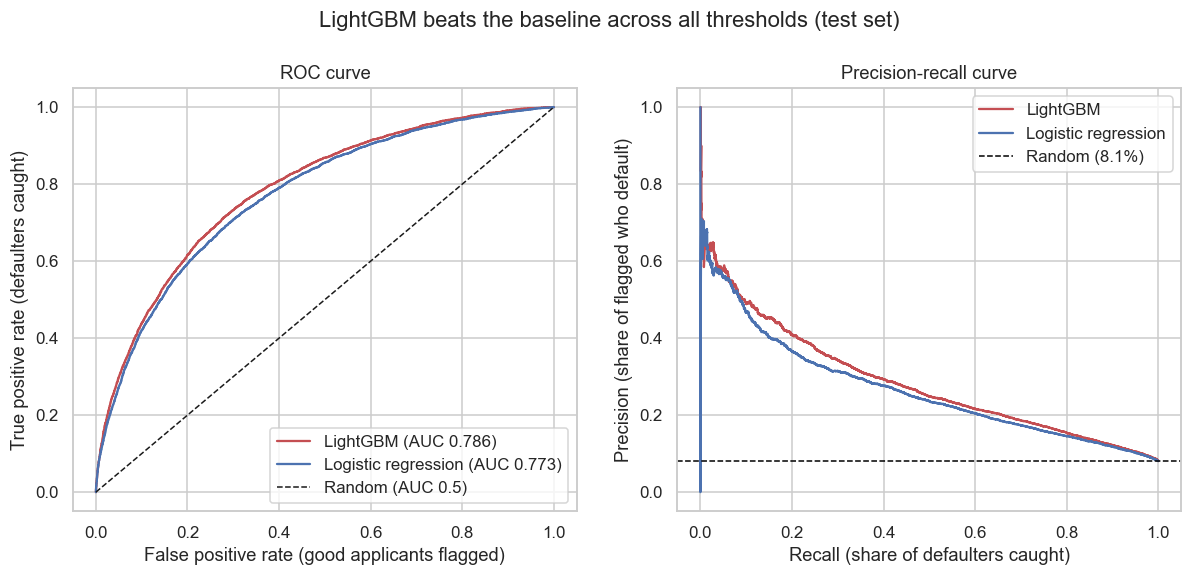

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p, color in [("LightGBM", pd_lgbm, "#C44E52"), ("Logistic regression", pd_logit, "#4C72B0")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC 0.5)")
axes[0].set(xlabel="False positive rate (good applicants flagged)", ylabel="True positive rate (defaulters caught)", title="ROC curve")
axes[1].axhline(y_test.mean(), color="black", ls="--", lw=1, label=f"Random ({y_test.mean():.1%})")
axes[1].set(xlabel="Recall (share of defaulters caught)", ylabel="Precision (share of flagged who default)", title="Precision-recall curve")
for ax in axes: ax.legend(loc="best")
fig.suptitle("LightGBM beats the baseline across all thresholds (test set)", y=1.02)
save(fig, "13_roc_pr_curves")
plt.show()

**Interpretation:** the LightGBM curve (red) sits **above** the baseline (blue) almost everywhere in both charts, so it's better at **every** possible cutoff, not just one. The precision-recall chart shows the realistic difficulty of this problem: to catch half of all defaulters, only about 1 in 4 flagged applicants would really default. That's exactly why a flagged applicant deserves a **second look** rather than an automatic decline.

### 6.2 Calibration: can we trust the probabilities?

We split the test applicants into 10 equal groups (deciles) by predicted PD and compare the **average predicted PD** with the **actual default rate** in each group. A well-calibrated model sits on the diagonal.

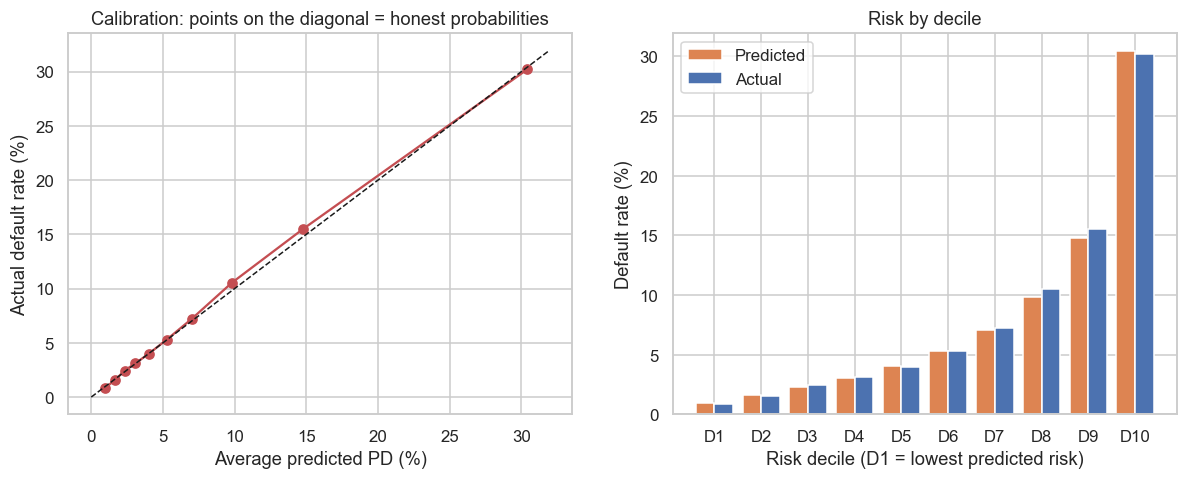

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
predicted PD,1.0000,1.7000,2.3000,3.1000,4.0000,5.3000,7.0000,9.8000,14.8000,30.4000
actual,0.8000,1.6000,2.4000,3.1000,4.0000,5.3000,7.2000,10.5000,15.5000,30.2000


In [9]:
deciles = pd.qcut(pd_lgbm, 10, labels=[f"D{i}" for i in range(1, 11)])
calib = pd.DataFrame({"predicted PD": pd_lgbm, "actual": y_test.values}).groupby(deciles, observed=True).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(calib["predicted PD"], calib["actual"], "o-", color="#C44E52")
lim = calib.max().max() * 1.05
axes[0].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set(xlabel="Average predicted PD (%)", ylabel="Actual default rate (%)", title="Calibration: points on the diagonal = honest probabilities")
x = np.arange(10)
axes[1].bar(x - 0.2, calib["predicted PD"], 0.4, label="Predicted", color="#DD8452")
axes[1].bar(x + 0.2, calib["actual"], 0.4, label="Actual", color="#4C72B0")
axes[1].set_xticks(x, calib.index)
axes[1].set(xlabel="Risk decile (D1 = lowest predicted risk)", ylabel="Default rate (%)", title="Risk by decile")
axes[1].legend()
save(fig, "14_calibration")
plt.show()
calib.T.round(1)

**Interpretation:**
- **The model is well calibrated:** in every decile, the predicted PD is within about one percentage point of the actual default rate. When SecondLook says "12% risk", about 12 in 100 such applicants really do default.
- **The model separates risk strongly:** the safest 10% of applicants default at under **1%**, while the riskiest 10% default at about **30%**, almost a **40× difference**. Compare that with the 8% average: the model turns one blurry average into very different, usable risk levels.

### 6.3 Which features does the model rely on?

**Gain importance** measures how much each feature improved the model's predictions across all its trees. This is a *global* view; in Step 5, SHAP will explain *individual* applicants.

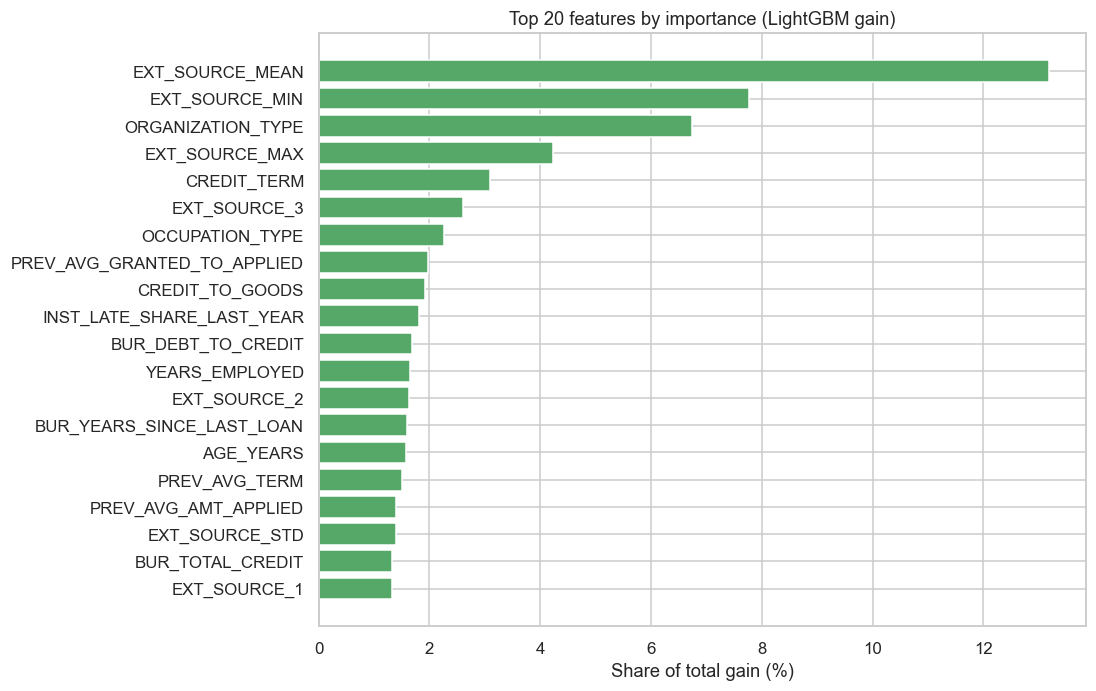

Top 20 features account for 61% of total gain


In [10]:
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=feats)
gain = (gain / gain.sum() * 100).sort_values(ascending=False)
top = gain.head(20)[::-1]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color="#55A868")
ax.set_xlabel("Share of total gain (%)")
ax.set_title("Top 20 features by importance (LightGBM gain)")
save(fig, "15_feature_importance")
plt.show()
print(f"Top 20 features account for {gain.head(20).sum():.0f}% of total gain")

**Interpretation:**
- **External scores dominate** (`EXT_SOURCE_MEAN`, `_MIN`, `_MAX` and the individual scores), as EDA predicted. The engineered average is the single most important feature.
- **Employer and job type** (`ORGANIZATION_TYPE`, `OCCUPATION_TYPE`) carry a lot of signal. Being categorical with many levels, they couldn't be screened with single-feature AUC in Step 3, but the model uses them heavily.
- **Loan structure features we engineered** rank high: `CREDIT_TERM` (number of payments) and `CREDIT_TO_GOODS` (borrowing above the item price). **These are things an applicant can change**, which is what makes the "path to approval" feature possible.
- **SQL history features** contribute too: previous loans granted vs applied, recent late payments, debt-to-credit at other lenders and recency of bureau loans.
- Age also appears. Age is not a lever we will ever suggest changing, and we will check in the fairness audit that the model doesn't treat age groups unfairly.

## 7. From scores to decisions: choosing the approval cutoff

A model outputs a PD; a lender needs **approve or decline**. The rule is: **approve if PD < cutoff**. The default cutoff of 0.5 makes no sense here (almost nobody has a 50% PD), so we choose the cutoff that **maximises expected profit**.

**Assumptions** (simple unit economics, stated openly; these are illustrative, not Home Credit's real figures):

| Outcome | Effect on profit |
|---|---|
| Approve an applicant who **repays** | **+15%** of the loan amount (interest and fees minus costs) |
| Approve an applicant who **defaults** | **−60%** of the loan amount (loss given default, after some recovery) |
| Decline | 0 |

So one default wipes out the profit of about **four** good loans of the same size. We compute total profit on the test set for every cutoff from 0.02 to 0.50.

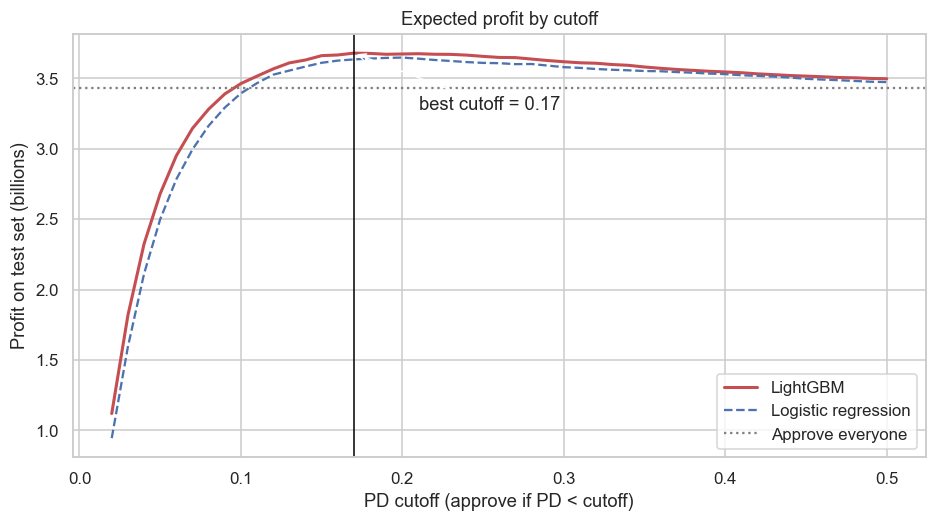

LightGBM profit vs approve-everyone: +7.2%


,profit (billions),approval rate,default rate of approved
Approve everyone,3.4332,1.0000,0.0807
Logistic regression (best cutoff),3.6474,0.9150,0.0597
LightGBM (best cutoff),3.6790,0.8819,0.0532


In [11]:
assumptions = M.ProfitAssumptions(margin=0.15, lgd=0.60)
curve = M.profit_curve(y_test, pd_lgbm, test["AMT_CREDIT"], assumptions)
curve_logit = M.profit_curve(y_test, pd_logit, test["AMT_CREDIT"], assumptions)
best = curve.loc[curve["profit"].idxmax()]
cutoff = float(best["cutoff"])
approve_all = M.approve_all_profit(y_test, test["AMT_CREDIT"], assumptions)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(curve["cutoff"], curve["profit"] / 1e9, color="#C44E52", lw=2, label="LightGBM")
ax1.plot(curve_logit["cutoff"], curve_logit["profit"] / 1e9, color="#4C72B0", lw=1.5, ls="--", label="Logistic regression")
ax1.axhline(approve_all / 1e9, color="grey", ls=":", label="Approve everyone")
ax1.axvline(cutoff, color="black", lw=1)
ax1.annotate(f"best cutoff = {cutoff:.2f}", (cutoff, best["profit"] / 1e9), xytext=(cutoff + 0.04, best["profit"] / 1e9 - 0.4),
             arrowprops=dict(arrowstyle="->"))
ax1.set(xlabel="PD cutoff (approve if PD < cutoff)", ylabel="Profit on test set (billions)", title="Expected profit by cutoff")
ax1.legend(loc="lower right")
save(fig, "16_profit_curve")
plt.show()

summary = pd.DataFrame({
    "profit (billions)": [approve_all / 1e9, curve_logit["profit"].max() / 1e9, best["profit"] / 1e9],
    "approval rate": [1.0, curve_logit.loc[curve_logit["profit"].idxmax(), "approval_rate"], best["approval_rate"]],
    "default rate of approved": [y_test.mean(), curve_logit.loc[curve_logit["profit"].idxmax(), "default_rate_approved"], best["default_rate_approved"]],
}, index=["Approve everyone", "Logistic regression (best cutoff)", "LightGBM (best cutoff)"])
print(f"LightGBM profit vs approve-everyone: {best['profit'] / approve_all - 1:+.1%}")
summary

**Interpretation:**
- **The most profitable cutoff is a PD of about 0.17**: approve anyone whose predicted default risk is below about 17%. At that cutoff the lender approves **about 88%** of applicants, and the default rate among approved loans falls from **8.1% to about 5.3%**.
- Profit rises **about 7% above approving everyone**, and LightGBM beats the logistic baseline. On a real lending book, a gain of that size is significant.
- The curve is **flat near the top** (cutoffs from about 0.15 to 0.22 give similar profit), so the decision isn't fragile. A lender with different margins or losses can re-run this with their own numbers: the assumptions are parameters, not hard-coded.

### 7.1 What happens at that cutoff? (confusion matrix)

Here the "positive" prediction is **decline** (PD ≥ cutoff).

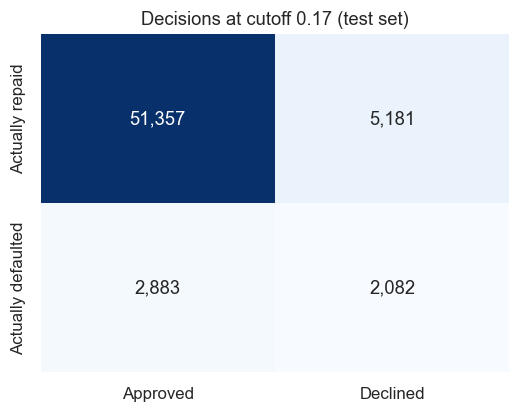

Precision (declined applicants who really default): 28.7%
Recall    (defaulters we decline):                 41.9%
Good applicants declined: 5,181   Defaulters approved: 2,883


In [12]:
decline = (pd_lgbm >= cutoff).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, decline).ravel()
cm = pd.DataFrame([[tn, fp], [fn, tp]],
                  index=["Actually repaid", "Actually defaulted"], columns=["Approved", "Declined"])

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"Decisions at cutoff {cutoff:.2f} (test set)")
save(fig, "17_confusion_matrix")
plt.show()

precision, recall = tp / (tp + fp), tp / (tp + fn)
print(f"Precision (declined applicants who really default): {precision:.1%}")
print(f"Recall    (defaulters we decline):                 {recall:.1%}")
print(f"Good applicants declined: {fp:,}   Defaulters approved: {fn:,}")

**Interpretation in lending terms:**
- **Recall ≈ 42%:** the model declines about **2 in 5 defaulters**, enough to cut the approved default rate from 8.1% to about 5.3%.
- **Precision ≈ 29%:** of the applicants it declines, **only about 3 in 10 would actually have defaulted. The other ~71% would have repaid.** That's about **5,200 good applicants** in this test set alone.
- Because a default costs about four times what a good loan earns, declining some good applicants is the profit-maximising choice *on average*. But **for each individual it is a lost opportunity**, and for a thin-file borrower it may be the difference between getting credit and turning to an informal lender.

**This is the SecondLook opportunity in one number:** most declined applicants would have repaid. The rest of this notebook looks at who they are.

## 8. Business value

### 8.1 More approvals at the same risk

How does the model compare with a simpler lending rule? A common approach is to rank applicants by an **external credit score only**. We compare: at the **same default rate among approved loans**, how many applicants can each approach approve?

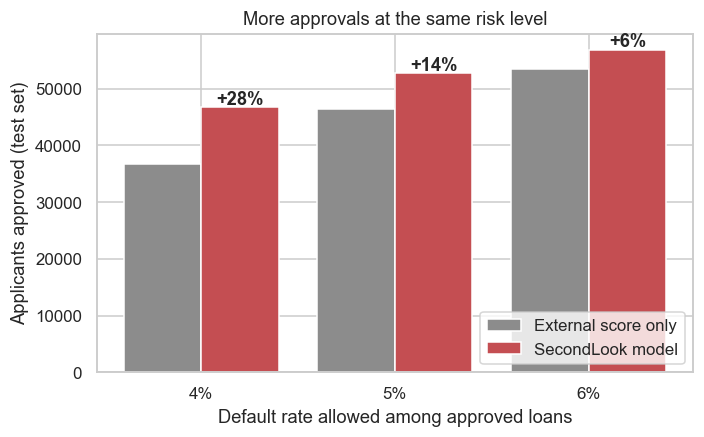

,score-only approvals,SecondLook model approvals,extra approvals,gain
target default rate,,,,
4%,"36,645","46,793","+10,148",+27.7%
5%,"46,371","52,755","+6,384",+13.8%
6%,"53,509","56,845","+3,336",+6.2%


In [13]:
ext_score = -test["EXT_SOURCE_MEAN"].fillna(test["EXT_SOURCE_MEAN"].median()).values   # higher = riskier
rows = []
for rate in [0.04, 0.05, 0.06]:
    n_model, _ = M.approvals_at_default_rate(y_test, pd_lgbm, rate)
    n_score, _ = M.approvals_at_default_rate(y_test, ext_score, rate)
    rows.append({"target default rate": f"{rate:.0%}", "score-only approvals": n_score,
                 "SecondLook model approvals": n_model, "extra approvals": n_model - n_score,
                 "gain": n_model / n_score - 1})
gain_table = pd.DataFrame(rows).set_index("target default rate")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(gain_table))
ax.bar(x - 0.2, gain_table["score-only approvals"], 0.4, label="External score only", color="#8C8C8C")
ax.bar(x + 0.2, gain_table["SecondLook model approvals"], 0.4, label="SecondLook model", color="#C44E52")
for i, g in enumerate(gain_table["gain"]):
    ax.text(i + 0.2, gain_table["SecondLook model approvals"].iloc[i] + 500, f"+{g:.0%}", ha="center", fontweight="bold")
ax.set_xticks(x, gain_table.index)
ax.set(xlabel="Default rate allowed among approved loans", ylabel="Applicants approved (test set)", title="More approvals at the same risk level")
ax.legend(loc="lower right")
save(fig, "18_approvals_gain")
plt.show()
gain_table.style.format({"score-only approvals": "{:,}", "SecondLook model approvals": "{:,}", "extra approvals": "{:+,}", "gain": "{:+.1%}"})

**Interpretation:** at the same level of risk, the model approves **many more applicants** than ranking by external score alone. At a **5% default rate**, it approves about **6,400 more applicants (+14%)** in this test set, and at a stricter 4% the gain is about **+28%**. These are real people who would otherwise be declined, approved **without adding risk**, because the model uses their full history (repayment behaviour, loan structure, job) instead of a single score.

This is the headline number for the pitch: *"At the same default rate, SecondLook approves about 14% more applicants."*

### 8.2 Does it work for thin-file applicants?

In [14]:
thin = test["HAS_BUREAU_HISTORY"].eq(0).values
approved = pd_lgbm < cutoff
thin_table = pd.DataFrame({
    "applicants": [thin.sum(), (~thin).sum()],
    "test AUC": [roc_auc_score(y_test[thin], pd_lgbm[thin]), roc_auc_score(y_test[~thin], pd_lgbm[~thin])],
    "actual default rate": [y_test[thin].mean(), y_test[~thin].mean()],
    "approval rate": [approved[thin].mean(), approved[~thin].mean()],
    "default rate of approved": [y_test[thin][approved[thin]].mean(), y_test[~thin][approved[~thin]].mean()],
}, index=["Thin file (no bureau record)", "Has bureau history"])
thin_table

,applicants,test AUC,actual default rate,approval rate,default rate of approved
Thin file (no bureau record),8776,0.7725,0.1014,0.8270,0.0630
Has bureau history,52727,0.7875,0.0773,0.8910,0.0516


**Interpretation:**
- For thin-file applicants the model still ranks risk well (**AUC ≈ 0.77**), only slightly below applicants with bureau history (≈ 0.79). So the model doesn't need a credit bureau record to work; it uses external scores, Home Credit history and the application itself.
- Thin-file applicants default at about **10%** overall, but the model approves **about 83%** of them, and the approved group defaults at only about **6.3%**. The model **finds the safe majority** within a riskier group, instead of declining the whole group.

### 8.3 Who are SecondLook's target applicants?

The applicants just above the cutoff are the ones a **second look** can help most: declined, but not by much.

In [15]:
declined = pd_lgbm >= cutoff
band = (pd_lgbm >= cutoff) & (pd_lgbm < cutoff + 0.05)
target_table = pd.DataFrame({
    "applicants": [declined.sum(), band.sum()],
    "share of all applicants": [declined.mean(), band.mean()],
    "actual default rate": [y_test[declined].mean(), y_test[band].mean()],
    "would have repaid": [1 - y_test[declined].mean(), 1 - y_test[band].mean()],
}, index=["All declined (PD ≥ cutoff)", f"Borderline (PD {cutoff:.2f}–{cutoff + 0.05:.2f})"])
target_table

,applicants,share of all applicants,actual default rate,would have repaid
All declined (PD ≥ cutoff),7263,0.1181,0.2867,0.7133
Borderline (PD 0.17–0.22),2611,0.0425,0.2026,0.7974


**Interpretation:**
- About **7,300 test applicants (12%)** are declined, and **about 71% of them would actually have repaid.**
- The **borderline group** (PD within 5 points above the cutoff) is about **2,600 applicants**, more than a third of all declines. About **80%** of them would have repaid.

This group is SecondLook's focus. For each borderline applicant, the app will:
1. **Explain** the decision with SHAP: which factors pushed the risk above the cutoff (Step 5).
2. **Search for a realistic path to approval**: e.g. a smaller loan or longer term that brings PD under the cutoff (Phase 2).
3. **Write a clear, honest letter** with Claude, and check it against the SHAP reasons (Step 6).

## 9. Save the model and its settings

We save everything the app and the next notebooks need:
- `models/lgbm_model.joblib`: the trained LightGBM model.
- `models/logistic_baseline.joblib`: the baseline, kept for comparison.
- `models/model_meta.json`: feature list, category lists, cutoff, profit assumptions, test metrics and the income cap from Step 3. The app reads this file so it scores new applicants **exactly** as the model was trained.
- `data/processed/test_predictions.parquet`: test-set predictions, used by SHAP (Step 5) and the fairness audit (Phase 2).

In [16]:
features_meta = json.loads(FEATURES_META.read_text())
meta = {
    "model": "LightGBM", "n_trees": n_trees, "params": {k: v for k, v in M.LGBM_PARAMS.items() if k != "n_estimators"},
    "features": feats, "categorical": cats, "categories": categories,
    "protected_cols": M.PROTECTED_COLS, "income_cap": features_meta["income_cap"],
    "cutoff": cutoff, "borderline_band": [cutoff, round(cutoff + 0.05, 2)],
    "profit_assumptions": assumptions,
    "metrics": {"cv_auc_mean": cv["mean_auc"], "cv_auc_std": cv["std_auc"],
                "test": lgbm_scores, "baseline_test": logit_scores,
                "precision_at_cutoff": precision, "recall_at_cutoff": recall,
                "approval_rate": float(best["approval_rate"]), "default_rate_approved": float(best["default_rate_approved"])},
    "split": {"test_size": M.TEST_SIZE, "random_state": RANDOM_STATE, "stratified": True},
}
M.save_model(lgbm, meta, baseline=logit)

preds = test[[ID_COL, TARGET_COL, "AMT_CREDIT", "HAS_BUREAU_HISTORY", "CODE_GENDER", "AGE_YEARS"]].copy()
preds["PD_LGBM"], preds["PD_LOGIT"] = pd_lgbm, pd_logit
preds["DECISION"] = np.where(pd_lgbm < cutoff, "approve", "decline")
preds["BORDERLINE"] = band
preds.to_parquet(PROCESSED_DIR / "test_predictions.parquet", index=False)

for path in [M.MODEL_PATH, M.BASELINE_PATH, M.META_PATH, PROCESSED_DIR / "test_predictions.parquet"]:
    print(f"Saved {path.relative_to(ROOT)}  ({path.stat().st_size / 1e6:.1f} MB)")

Saved models\lgbm_model.joblib  (4.4 MB)
Saved models\logistic_baseline.joblib  (0.0 MB)
Saved models\model_meta.json  (0.0 MB)
Saved data\processed\test_predictions.parquet  (1.9 MB)


## 10. Summary

| Question | Answer |
|---|---|
| Best model | **LightGBM**, test ROC AUC **≈ 0.786** (5-fold CV 0.784 ± 0.002), vs **0.773** for logistic regression |
| Does it generalise? | Yes: test AUC equals CV AUC, and the result is stable across folds |
| Are the probabilities honest? | Yes: predicted and actual default rates match within about 1 point in every decile; no class weights, by design |
| Risk separation | Safest 10% default at under 1%, riskiest 10% at about 30% |
| Decision rule | Approve if PD < **0.17** (profit-maximising under +15% / −60% assumptions): ~88% approved, 5.3% default rate among approved, about +7% profit vs approving everyone |
| Business value | **~14% more approvals at the same 5% default rate** than ranking by external score alone |
| Thin files | AUC ≈ 0.77; ~83% approved with a 6.3% default rate (vs 10% for the group overall) |
| SecondLook opportunity | **~71% of declined applicants would have repaid**; ~2,600 borderline applicants in the test set |
| Responsible AI | Gender excluded from inputs; age is never a lever; fairness audit in Phase 2 |

**Next: Step 5, explainability with SHAP**: for any applicant, show *why* the model gave that score, as the basis for the decision letter and the path to approval.